In [15]:
import networkx as nx
import torch
import numpy as np
from torch_geometric.utils.convert import to_networkx
from params import FAT_SIFT_DIR, COCO_DIR
from graphdataset import *
from cocodataset import *
import random

from params import *

from torch_geometric.data import DataLoader, Batch
from torch_geometric.data.data import Data
from torch.utils.data import DataLoader as UtilsDataLoader
from torch.utils.data import Sampler, BatchSampler

import matplotlib.pyplot as plt

In [24]:
graph_dataset = CocoDataset(root='../data/' + 'coco_3d_corners/')

In [31]:
def convert_graph_to_nx(idx):
    graph = graph_dataset[idx]
    graph2 = Data()
    for key in graph.keys:
        if(key != 'hash'):
            graph2[key] = graph[key]
        if(key == 'y'):
            graph2[key] = graph2[key].reshape(graph2[key].shape[0])
            
    xxgraph = to_networkx(graph2)
    node_labels = graph2.y[list(xxgraph.nodes)].numpy()
    
    feature_idx = np.argmax(graph2.y)
    node_labels = ['r' if(i != feature_idx) else 'b' for i in range(len(graph2.y))]
    
    return xxgraph, node_labels

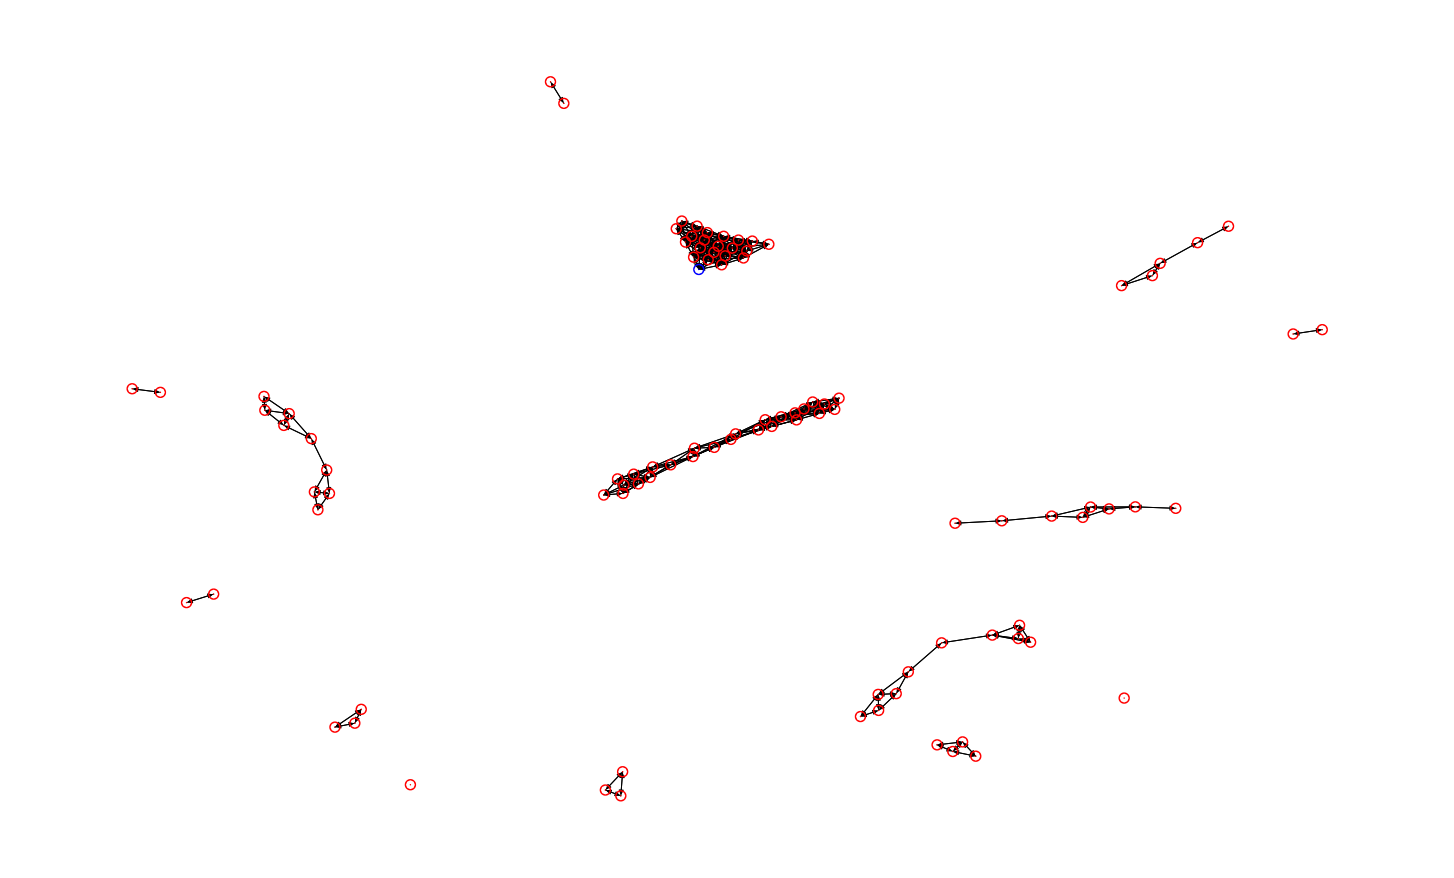

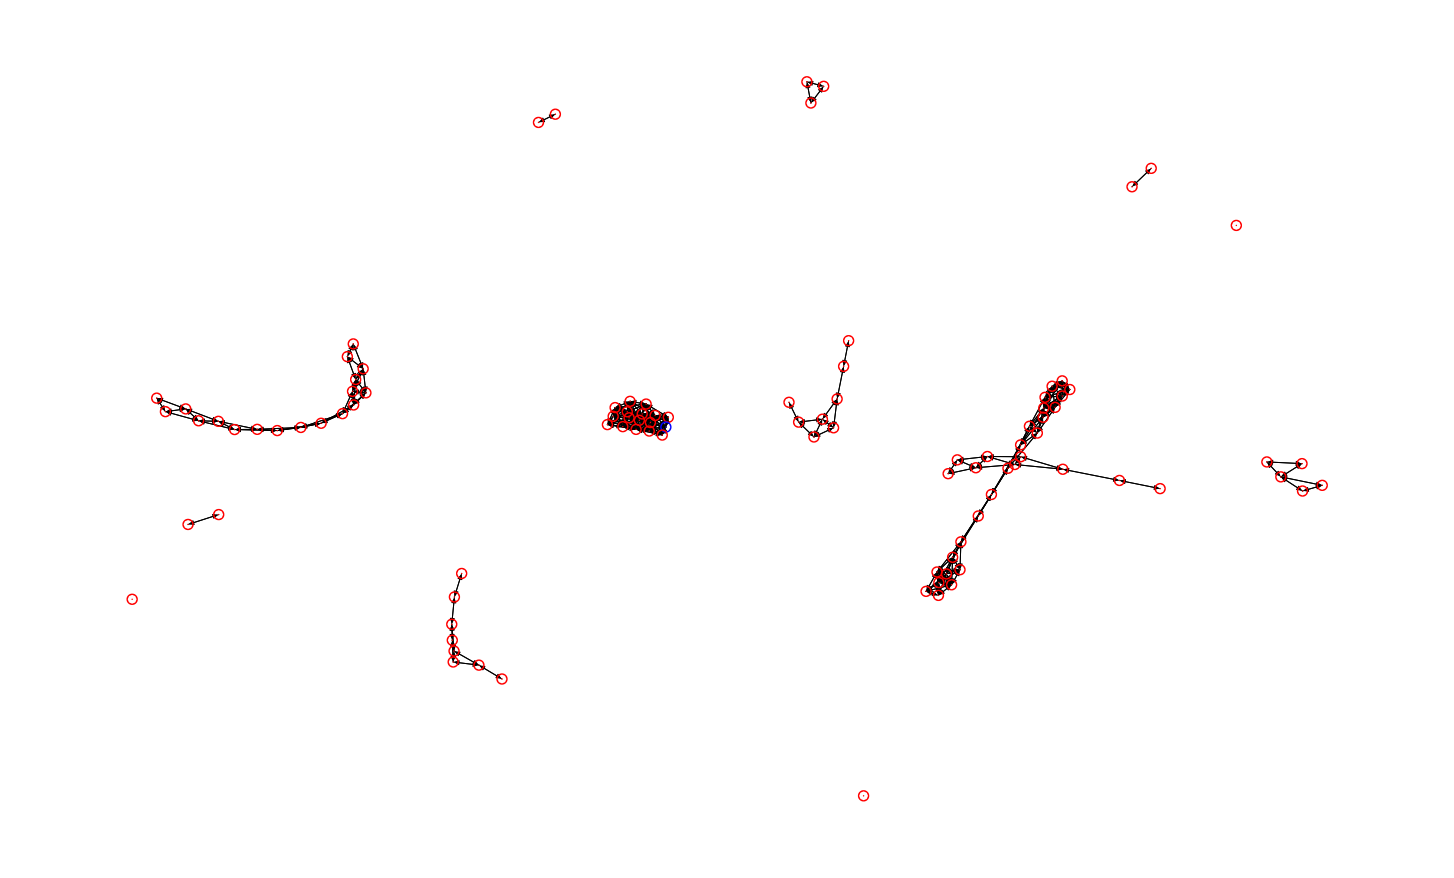

In [32]:
idx1 = 20
idx2 = idx1 + 1

g1, l1 = convert_graph_to_nx(idx1)
g2, l2 = convert_graph_to_nx(idx2)

plt.figure(1, figsize=(20, 12))
nx.draw(g1, cmap=plt.get_cmap('Set1'), node_color = l1, node_size=2, linewidths=10)
plt.figure(2, figsize=(20, 12)) 
nx.draw(g2, cmap=plt.get_cmap('Set2'), node_color = l2, node_size=2, linewidths=10)
plt.show()